# Complete analysis
In this notebook we combine the results from `tapo-analysis-conf`1,2,3,4,5,6`.ipynb` to compute the measured total energy consumption of all pipeline configurations.

## pipeline configurations
Six pipeline configurations: conf-1, conf-2, conf-3, conf-4, conf-5, conf-6
Each pipeline config was run 4 times.

## time shifts
* We do not know/understand why there are time diffs between the start time in SIMPIPE and the surge times discovered/reported by the Tapo device.
* `simpipe_datetime_shift`provide overall best guess of the time shift. But this was just used initially. We rather rely on the measured diff for each measurement.
* `surge_time_diff` is the measured time diff between the start time of the Tapo energy surge identified, and what SIMPIPE provides as timestamp. (this is what we use to shift the data)


In [1]:
import pandas as pd
import numpy as np
import sys
from pathlib import Path

sys.path.append(str(Path.cwd().parent))

from analysis_functions import get_time_periods, get_power_data, divide_power_data_into_step_periods, compute_relative_energy_usage, compute_baseline_stats

In [2]:
base_path = "../../data/carbontracker"
surge_time_diffs = pd.read_csv(f"{base_path}/surge_time_diffs.dat", sep=r'\s+', comment='#', header=0)

In [3]:
surge_time_diffs.head(4*6)

,configuration,runNr,startDiff,endDiff,duration
0,conf-1,1,138.9,118.9,205.1
1,conf-1,2,152.2,118.3,208.9
2,conf-1,3,123.0,118.6,204.4
3,conf-1,4,141.9,117.6,204.3
4,conf-2,1,135.4,115.3,200.1
5,conf-2,2,126.7,86.6,200.2
6,conf-2,3,150.1,109.9,200.2
7,conf-2,4,122.2,113.5,203.7
8,conf-3,1,152.2,119.2,198.0
9,conf-3,2,150.7,88.0,197.7


In [4]:
datasets = {
    "conf-1": {
        "simpipe_datetime_shift": 112, # shift simpipe_data by this amount of minutes (from comparison_analysis.ipynb average Delta value)
        "run1": {
            "surge_time_diff": float(surge_time_diffs[surge_time_diffs.configuration == "conf-1"][surge_time_diffs.runNr == 1].values[0][2]),
            "start_time_baseline": '2025-09-01 00:00:00', 
            "end_time_baseline": '2025-09-01 06:00:00',
            "start_time_pipeline": '2025-09-01 06:21:04',
            "end_time_pipeline": '2025-09-01 09:46:07'
            },
        "run2": {
            "surge_time_diff": float(surge_time_diffs[surge_time_diffs.configuration == "conf-1"][surge_time_diffs.runNr == 2].values[0][2]),
            "start_time_baseline": '2025-09-01 13:00:00', 
            "end_time_baseline": '2025-09-01 20:00:40',
            "start_time_pipeline": '2025-09-01 21:07:47',
            "end_time_pipeline": '2025-09-02 00:36:43'
            },
        "run3": {
            "surge_time_diff": float(surge_time_diffs[surge_time_diffs.configuration == "conf-1"][surge_time_diffs.runNr == 3].values[0][2]),
            "start_time_baseline": '2025-09-02 00:00:00', 
            "end_time_baseline": '2025-09-02 05:00:00',
            "start_time_pipeline": '2025-09-02 05:26:59',
            "end_time_pipeline": '2025-09-02 08:51:24'
            },
        "run4": {
            "surge_time_diff": float(surge_time_diffs[surge_time_diffs.configuration == "conf-1"][surge_time_diffs.runNr == 4].values[0][2]),
            "start_time_baseline": '2025-09-02 00:00:00',
            "end_time_baseline": '2025-09-02 05:00:00',
            "start_time_pipeline": '2025-09-02 12:04:58',
            "end_time_pipeline": '2025-09-02 15:29:18'
            },
    },
    "conf-2": {
        "simpipe_datetime_shift": 112, # shift simpipe_data by this amount of minutes (from comparison_analysis.ipynb average Delta value)        
        "run1": {
            "surge_time_diff": float(surge_time_diffs[surge_time_diffs.configuration == "conf-2"][surge_time_diffs.runNr == 1].values[0][2]),
            "start_time_baseline": '2025-08-31 03:00:00',
            "end_time_baseline": '2025-08-31 14:00:00',
            "start_time_pipeline": '2025-08-31 13:09:34',
            "end_time_pipeline": '2025-08-31 16:29:43'},
        "run2": {
            "surge_time_diff": float(surge_time_diffs[surge_time_diffs.configuration == "conf-2"][surge_time_diffs.runNr == 2].values[0][2]),
            "start_time_baseline": '2025-08-31 09:00:00', 
            "end_time_baseline": '2025-08-31 15:00:00',
            "start_time_pipeline": '2025-08-31 17:43:17',
            "end_time_pipeline": '2025-08-31 21:03:26'},
        "run3": {
            "surge_time_diff": float(surge_time_diffs[surge_time_diffs.configuration == "conf-2"][surge_time_diffs.runNr == 3].values[0][2]),
            "start_time_baseline": '2025-09-02 03:00:00', 
            "end_time_baseline": '2025-09-02 07:00:00',
            "start_time_pipeline": '2025-09-02 14:54:55',
            "end_time_pipeline": '2025-09-02 18:15:04'},
        "run4": {
            "surge_time_diff": float(surge_time_diffs[surge_time_diffs.configuration == "conf-2"][surge_time_diffs.runNr == 4].values[0][2]),
            "start_time_baseline": '2025-09-08 15:00:00', 
            "end_time_baseline": '2025-09-09 05:00:00',
            "start_time_pipeline": '2025-09-09 06:12:51',
            "end_time_pipeline": '2025-09-09 09:36:31'},
    },
    "conf-3": {
        "simpipe_datetime_shift": 112, # shift simpipe_data by this amount of minutes (from best guess startDiff)
        "run1": {
            "surge_time_diff": float(surge_time_diffs[surge_time_diffs.configuration == "conf-3"][surge_time_diffs.runNr == 1].values[0][2]),
            "start_time_baseline": '2025-08-30 15:00:00', 
            "end_time_baseline": '2025-08-30 19:00:00',
            "start_time_pipeline": '2025-08-30 19:57:50',
            "end_time_pipeline": '2025-08-30 23:15:49'},
        "run2": {
            "surge_time_diff": float(surge_time_diffs[surge_time_diffs.configuration == "conf-3"][surge_time_diffs.runNr == 2].values[0][2]),
            "start_time_baseline": '2025-09-03 04:00:00', 
            "end_time_baseline": '2025-09-03 06:00:00',
            "start_time_pipeline": '2025-09-03 06:24:19',
            "end_time_pipeline": '2025-09-03 09:42:00'},
        "run3": {
            "surge_time_diff": float(surge_time_diffs[surge_time_diffs.configuration == "conf-3"][surge_time_diffs.runNr == 3].values[0][2]),
            "start_time_baseline": '2025-09-08 19:00:00', 
            "end_time_baseline": '2025-09-09 03:00:00',
            "start_time_pipeline": '2025-09-09 12:52:27',
            "end_time_pipeline": '2025-09-09 16:15:40'},
        "run4": {
            "surge_time_diff": float(surge_time_diffs[surge_time_diffs.configuration == "conf-3"][surge_time_diffs.runNr == 4].values[0][2]),
            "start_time_baseline": '2025-09-09 19:00:00', 
            "end_time_baseline": '2025-09-09 20:30:00',
            "start_time_pipeline": '2025-09-09 21:11:27',
            "end_time_pipeline": '2025-09-10 00:30:22'},
    },
    "conf-4": {
        "simpipe_datetime_shift": 121.0, # shift simpipe_data by this amount of minutes (best guess startDiff)
        "run1": {
            "surge_time_diff": float(surge_time_diffs[surge_time_diffs.configuration == "conf-4"][surge_time_diffs.runNr == 1].values[0][2]),
            "start_time_baseline": '2025-09-10 03:00:00', 
            "end_time_baseline": '2025-09-10 05:30:00',
            "start_time_pipeline": '2025-09-10 06:03:58',
            "end_time_pipeline": '2025-09-10 08:05:41'},
        "run2": {
            "surge_time_diff": float(surge_time_diffs[surge_time_diffs.configuration == "conf-4"][surge_time_diffs.runNr == 2].values[0][2]),
            "start_time_baseline": '2025-08-29 11:30:00', 
            "end_time_baseline": '2025-08-29 13:00:00',
            "start_time_pipeline": '2025-08-29 13:37:05',
            "end_time_pipeline": '2025-08-29 15:37:11'},
        "run3": {
            "surge_time_diff": float(surge_time_diffs[surge_time_diffs.configuration == "conf-4"][surge_time_diffs.runNr == 3].values[0][2]),
            "start_time_baseline": '2025-08-30 00:00:00', 
            "end_time_baseline": '2025-08-30 07:30:00',
            "start_time_pipeline": '2025-08-30 08:19:09',
            "end_time_pipeline": '2025-08-30 10:19:40'},
        "run4": {
            "surge_time_diff": float(surge_time_diffs[surge_time_diffs.configuration == "conf-4"][surge_time_diffs.runNr == 4].values[0][2]),
            "start_time_baseline": '2025-09-10 11:00:00', 
            "end_time_baseline": '2025-09-10 19:00:00',
            "start_time_pipeline": '2025-09-10 19:53:05',
            "end_time_pipeline": '2025-09-10 21:53:41'},
    },
    "conf-5": {
        "simpipe_datetime_shift": 122.0, # shift simpipe_data by this best guess
        "run1": {
            "surge_time_diff": float(surge_time_diffs[surge_time_diffs.configuration == "conf-5"][surge_time_diffs.runNr == 1].values[0][2]),
            "start_time_baseline": '2025-09-11 18:00:00', 
            "end_time_baseline": '2025-09-12 06:30:00',
            "start_time_pipeline": '2025-09-12 07:01:00',
            "end_time_pipeline": '2025-09-12 11:25:11'},
        "run2": {
            "surge_time_diff": float(surge_time_diffs[surge_time_diffs.configuration == "conf-5"][surge_time_diffs.runNr == 2].values[0][2]),
            "start_time_baseline": '2025-09-12 21:00:00', 
            "end_time_baseline": '2025-09-13 12:30:00',
            "start_time_pipeline": '2025-09-13 12:52:13',
            "end_time_pipeline": '2025-09-13 17:17:05'},
        "run3": {
            "surge_time_diff": float(surge_time_diffs[surge_time_diffs.configuration == "conf-5"][surge_time_diffs.runNr == 3].values[0][2]),
            "start_time_baseline": '2025-09-14 01:00:00', 
            "end_time_baseline": '2025-09-14 11:30:00',
            "start_time_pipeline": '2025-09-14 11:54:17',
            "end_time_pipeline": '2025-09-14 16:18:06'},
        "run4": {
            "surge_time_diff": float(surge_time_diffs[surge_time_diffs.configuration == "conf-5"][surge_time_diffs.runNr == 4].values[0][2]),
            "start_time_baseline": '2025-09-14 19:00:00', 
            "end_time_baseline": '2025-09-15 06:45:00',
            "start_time_pipeline": '2025-09-15 07:15:49',
            "end_time_pipeline": '2025-09-15 11:45:42'},
    },
    "conf-6": {
        "simpipe_datetime_shift": 120.6,
        "run1": {
            "surge_time_diff": float(surge_time_diffs[surge_time_diffs.configuration == "conf-6"][surge_time_diffs.runNr == 1].values[0][2]),
            "start_time_baseline": '2025-09-04 00:00:00', 
            "end_time_baseline": '2025-09-04 11:00:00',
            "start_time_pipeline": '2025-09-04 11:15:16',
            "end_time_pipeline": '2025-09-04 13:14:15'},
        "run2": {
            "surge_time_diff": float(surge_time_diffs[surge_time_diffs.configuration == "conf-6"][surge_time_diffs.runNr == 2].values[0][2]),
            "start_time_baseline": '2025-09-11 00:30:00', 
            "end_time_baseline": '2025-09-11 06:30:00',
            "start_time_pipeline": '2025-09-11 06:59:23',
            "end_time_pipeline": '2025-09-11 08:56:30'},
        "run3": {
            "surge_time_diff": float(surge_time_diffs[surge_time_diffs.configuration == "conf-6"][surge_time_diffs.runNr == 3].values[0][2]),
            "start_time_baseline": '2025-09-11 11:30:00', 
            "end_time_baseline": '2025-09-11 12:30:00',
            "start_time_pipeline": '2025-09-11 13:02:39',
            "end_time_pipeline": '2025-09-11 15:00:56'},
        "run4": {
            "surge_time_diff": float(surge_time_diffs[surge_time_diffs.configuration == "conf-6"][surge_time_diffs.runNr == 4].values[0][2]),
            "start_time_baseline": '2025-09-05 15:00:00', 
            "end_time_baseline": '2025-09-05 21:00:00',
            "start_time_pipeline": '2025-09-05 21:48:22',
            "end_time_pipeline": '2025-09-05 23:45:25'},
    },
}

/var/folders/9x/df97rq2j35gg_bpq8dzj7wz40000gn/T/ipykernel_79295/2698272259.py:5: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  "surge_time_diff": float(surge_time_diffs[surge_time_diffs.configuration == "conf-1"][surge_time_diffs.runNr == 1].values[0][2]),
/var/folders/9x/df97rq2j35gg_bpq8dzj7wz40000gn/T/ipykernel_79295/2698272259.py:12: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  "surge_time_diff": float(surge_time_diffs[surge_time_diffs.configuration == "conf-1"][surge_time_diffs.runNr == 2].values[0][2]),
/var/folders/9x/df97rq2j35gg_bpq8dzj7wz40000gn/T/ipykernel_79295/2698272259.py:19: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  "surge_time_diff": float(surge_time_diffs[surge_time_diffs.configuration == "conf-1"][surge_time_diffs.runNr == 3].values[0][2]),
/var/folders/9x/df97rq2j35gg_bpq8dzj7wz40000gn/T/ipykernel_79295/2698272259.py:26: UserWarning: Boolean Series key will be reind

In [5]:
def analyze_data(
        simpipe_data: pd.DataFrame, 
        tapo_power_data: pd.DataFrame, 
        simpipe_datetime_shift: float = 0,
        start_time_baseline: str = None,
        end_time_baseline: str = None):
    """
    Analyze the data from the simulation pipe and Tapo power data.

    Baseline energy comes in two flavours (see analysis_functions.compute_relative_energy_usage):
    - tapo_be: baseline energy PER TAPO SAMPLE (kWh/sample) -- a rate, not a total.
    - tapo_BE: baseline energy TOTALED over the surge/pipeline window (kWh), i.e.
      tapo_be * n_samples. This is the quantity comparable to AE and RE: AE == BE + RE.
    """
    if simpipe_datetime_shift != 0:
        simpipe_data = simpipe_data.copy()
        # Convert start and stop columns to datetime if they aren't already
        simpipe_data["start"] = pd.to_datetime(simpipe_data["start"])
        simpipe_data["stop"] = pd.to_datetime(simpipe_data["stop"])
        # Apply shift
        simpipe_data["start"] += pd.Timedelta(minutes=simpipe_datetime_shift)
        simpipe_data["stop"] += pd.Timedelta(minutes=simpipe_datetime_shift)
    
    tapo_time_periods = get_time_periods(simpipe_data, start_date_baseline=start_time_baseline, end_date_baseline=end_time_baseline)
    tapo_baseline_stats = compute_baseline_stats(df=tapo_power_data, percentile_threshold=70, print_stats=True) # compute baseline stats automatically.
    tapo_segmented_power_data = divide_power_data_into_step_periods(tapo_time_periods, tapo_power_data)
    tapo_relative_energy_usage, tapo_be, tapo_total_absolute_energy, tapo_total_relative_energy = compute_relative_energy_usage(tapo_segmented_power_data, tapo_time_periods,tapo_baseline_stats)
    # BE: baseline energy totaled over the surge/pipeline window -- comparable to AE and RE (AE == BE + RE)
    tapo_BE = tapo_relative_energy_usage["BE(kWh)"].sum() if not tapo_relative_energy_usage.empty else 0
    return {
        "time_periods": tapo_time_periods,
        "tapo_segmented_power_data": tapo_segmented_power_data,
        "tapo_relative_energy_usage": tapo_relative_energy_usage,
        "tapo_be": tapo_be,
        "tapo_BE": tapo_BE,
        "tapo_total_absolute_energy": tapo_total_absolute_energy,
        "tapo_total_relative_energy": tapo_total_relative_energy,
        "simpipe_data": simpipe_data,
        "simpipe_total_energy": simpipe_data["energy"].sum(),
        "simpipe_pipeline_duration": (simpipe_data["stop"] - simpipe_data["start"]).sum().total_seconds()
    }

In [6]:
# Compute results

results = {
    "conf-1": [],
    "conf-2": [],
    "conf-3": [],
    "conf-4": [],
    "conf-5": [],
    "conf-6": []
}
for confNr in ["conf-1", "conf-2", "conf-3", "conf-4", "conf-5", "conf-6"]:
    print()
    print(f"=== PROCESSING {confNr} ===")
    for runNr in ["run1", "run2", "run3", "run4"]:
        print()
        print(f"  --- Processing {runNr}...")
        path_simpipe_data = f"{base_path}/{confNr}/{runNr}.dat"
        path_tapo_data = f"{base_path}/{confNr}/power-{runNr}.xls"
        simpipe_data = pd.read_csv(path_simpipe_data, sep=r'\s+', comment='#', header=0)
        if simpipe_data["energy"].dtype == 'object':
            raise ValueError(f"Invalid data type for energy column in {path_simpipe_data}")
        tapo_power_data = get_power_data(path_tapo_data) # get tapo power data
        tapo_power_data = tapo_power_data.assign(
            **{"Power(W)": pd.to_numeric(tapo_power_data["Power(W)"]).astype(float)}
        )
        #simpipe_datetime_shift = datasets[confNr]["simpipe_datetime_shift"]
        simpipe_datetime_shift = datasets[confNr][runNr]["surge_time_diff"]
        start_time_baseline = datasets[confNr][runNr]["start_time_baseline"]
        end_time_baseline = datasets[confNr][runNr]["end_time_baseline"]
        r = analyze_data(
            simpipe_data=simpipe_data,
            tapo_power_data=tapo_power_data,
            simpipe_datetime_shift=simpipe_datetime_shift,
            start_time_baseline=start_time_baseline,
            end_time_baseline=end_time_baseline)
        results[confNr].append({"confNr": confNr, "runNr": runNr, **r})


=== PROCESSING conf-1 ===

  --- Processing run1...
    get_time_periods -- start and end times present. Assuming baseline period.
     appending baseline period
    get_time_periods -- extracted time periods:
      - baseline: 2025-09-01 00:00:00 to 2025-09-01 06:00:00
      - trimming: 2025-09-01 08:39:58 to 2025-09-01 09:04:08
      - alignment-bwa: 2025-09-01 09:04:18 to 2025-09-01 11:29:10
      - mark-duplicates: 2025-09-01 11:29:20 to 2025-09-01 11:59:34
      - create-fasta-dict: 2025-09-01 11:59:44 to 2025-09-01 12:00:54
      - create-fasta-index: 2025-09-01 12:01:03 to 2025-09-01 12:01:52
      - base-quality-score: 2025-09-01 12:02:02 to 2025-09-01 12:05:01
     compute_baseline_stats -- Baseline analysis...
      Power threshold for baseline: 207.0 W
      Baseline periods: 210 out of 288 (72.9%)
      Mean baseline power: 202.9 W
      Median baseline power: 203.0 W
      Std baseline power: 2.2 W
      Power range: 199.0 - 207.0 W
      Mean baseline energy per period: 

    get_time_periods -- start and end times present. Assuming baseline period.
     appending baseline period
    get_time_periods -- extracted time periods:
      - baseline: 2025-09-10 11:00:00 to 2025-09-10 19:00:00
      - trimming: 2025-09-10 21:54:59 to 2025-09-10 22:14:22
      - alignment: 2025-09-10 22:14:32 to 2025-09-10 23:28:45
      - mark-duplicates: 2025-09-10 23:28:55 to 2025-09-10 23:52:00
      - create-fasta-index: 2025-09-10 23:52:10 to 2025-09-10 23:53:08
      - base-quality-score: 2025-09-10 23:53:18 to 2025-09-10 23:55:35
     compute_baseline_stats -- Baseline analysis...
      Power threshold for baseline: 207.0 W
      Baseline periods: 212 out of 288 (73.6%)
      Mean baseline power: 203.3 W
      Median baseline power: 203.0 W
      Std baseline power: 2.2 W
      Power range: 195.0 - 207.0 W
      Mean baseline energy per period: 0.016940 kWh
      Total baseline energy: 3.5913 kWh


     divide_power_data_into_step_periods...
        Processing baseline.

In [7]:
# Analyse the results
final_results = pd.DataFrame(
    columns=["conf", "tapo_be_avg", "tapo_be_std", "tapo_BE_avg", "tapo_BE_std", "tapo_absolute_energy_avg", "tapo_absolute_energy_std", "tapo_relative_energy_avg", "tapo_relative_energy_std", "simpipe_energy_avg", "simpipe_energy_std", "simpipe_duration_avg", "simpipe_duration_std"]
)
final_results_details = pd.DataFrame(
    columns=["conf", "runNr", "tapo_be", "tapo_BE", "tapo_total_relative_energy", "tapo_total_absolute_energy", "simpipe_total_energy", "simpipe_duration"]
)
print("=== Analysis of the results ==================================================================")
print("""
    be  = Baseline Energy rate (kWh per Tapo sample) -- NOT a window total
    BE  = Baseline Energy totaled over the surge/pipeline window (kWh) = be * n_samples
    RE  = Relative Tapo Energy, above baseline, over the surge/pipeline window (kWh)
    AE  = Absolute Tapo Energy over the surge/pipeline window (kWh)
    SE  = SIMPIPE Energy (kWh)
    SD  = SIMPIPE Duration

    Identity: AE == BE + RE  (both expressed as window totals, in kWh)
""")
for conf in results:
    print()
    print(f"=== RESULTS FOR {conf} ==================================================================")
    print("    Run :    be       BE       RE       AE     BE+RE      SE       |   SD")
    print("-----------------------------------------------------------------------------------------")
    be_rates = [result['tapo_be'] for result in results[conf]]
    baseline_energies = [result['tapo_BE'] for result in results[conf]]
    tapo_relative_energies = [result['tapo_total_relative_energy'] for result in results[conf]]
    tapo_absolute_energies = [result['tapo_total_absolute_energy'] for result in results[conf]]
    simpipe_energies = [result['simpipe_total_energy'] for result in results[conf]]
    simpipe_durations = [result['simpipe_pipeline_duration'] for result in results[conf]]
    
    avg_be_rate = np.mean(be_rates)
    avg_baseline_energy = np.mean(baseline_energies)
    avg_tapo_absolute_energy = np.mean(tapo_absolute_energies)
    avg_tapo_relative_energy = np.mean(tapo_relative_energies)
    avg_simpipe_energy = np.mean(simpipe_energies)
    avg_simpipe_duration = np.mean(simpipe_durations)

    std_be_rate = np.std(be_rates)
    std_baseline_energy = np.std(baseline_energies)
    std_tapo_absolute_energy = np.std(tapo_absolute_energies)
    std_tapo_relative_energy = np.std(tapo_relative_energies)
    std_simpipe_energy = np.std(simpipe_energies)
    std_simpipe_duration = np.std(simpipe_durations)

    final_results = pd.concat([final_results, pd.DataFrame([{
        "conf": conf,
        "tapo_be_avg": avg_be_rate,
        "tapo_be_std": std_be_rate,
        "tapo_BE_avg": avg_baseline_energy,
        "tapo_BE_std": std_baseline_energy,
        "tapo_absolute_energy_avg": avg_tapo_absolute_energy,
        "tapo_absolute_energy_std": std_tapo_absolute_energy,
        "tapo_relative_energy_avg": avg_tapo_relative_energy,
        "tapo_relative_energy_std": std_tapo_relative_energy,
        "simpipe_energy_avg": avg_simpipe_energy,
        "simpipe_energy_std": std_simpipe_energy,
        "simpipe_duration_avg": avg_simpipe_duration,
        "simpipe_duration_std": std_simpipe_duration
    }])], ignore_index=True)

    for result in results[conf]:
        final_results_details = pd.concat([final_results_details, pd.DataFrame([{
            "conf": conf,
            "runNr": result['runNr'],
            "tapo_be": result['tapo_be'],
            "tapo_BE": result['tapo_BE'],
            "tapo_total_relative_energy": result['tapo_total_relative_energy'],
            "tapo_total_absolute_energy": result['tapo_total_absolute_energy'],
            "simpipe_total_energy": result['simpipe_total_energy'],
            "simpipe_duration": result['simpipe_pipeline_duration']
        }])], ignore_index=True)

        be_plus_re = result['tapo_BE'] + result['tapo_total_relative_energy']
        print(f"    {result['runNr']} : {result['tapo_be']:.4f}   {result['tapo_BE']:.4f}  {result['tapo_total_relative_energy']:.4f}  {result['tapo_total_absolute_energy']:.4f}  {be_plus_re:.4f}  {result['simpipe_total_energy']:.4f}     |   {result['simpipe_pipeline_duration']:.1f} seconds (in {result['simpipe_pipeline_duration']/3600:.2f} hours)")
    print("-----------------------------------------------------------------------------------------")    
    avg_be_plus_re = avg_baseline_energy + avg_tapo_relative_energy
    print(f"    AVG : {avg_be_rate:.4f}   {avg_baseline_energy:.4f}  {avg_tapo_relative_energy:.4f}  {avg_tapo_absolute_energy:.4f}  {avg_be_plus_re:.4f}  {avg_simpipe_energy:.4f}     |   {avg_simpipe_duration:.1f} seconds (in {avg_simpipe_duration/3600:.2f} hours)")
    print(f"    STD : {std_be_rate:.4f}   {std_baseline_energy:.4f}  {std_tapo_relative_energy:.4f}  {std_tapo_absolute_energy:.4f}            {std_simpipe_energy:.4f}     |   {std_simpipe_duration:.1f} seconds (in {std_simpipe_duration/3600:.2f} hours)")
    print("=========================================================================================")

=== Analysis of the results ==================================================================

    be  = Baseline Energy rate (kWh per Tapo sample) -- NOT a window total
    BE  = Baseline Energy totaled over the surge/pipeline window (kWh) = be * n_samples
    RE  = Relative Tapo Energy, above baseline, over the surge/pipeline window (kWh)
    AE  = Absolute Tapo Energy over the surge/pipeline window (kWh)
    SE  = SIMPIPE Energy (kWh)
    SD  = SIMPIPE Duration

    Identity: AE == BE + RE  (both expressed as window totals, in kWh)


=== RESULTS FOR conf-1 ==================================================================
    Run :    be       BE       RE       AE     BE+RE      SE       |   SD
-----------------------------------------------------------------------------------------
    run1 : 0.0169   0.7101  0.3171  1.0272  1.0272  0.3846     |   12254.0 seconds (in 3.40 hours)
    run2 : 0.0170   0.7133  0.2717  0.9850  0.9850  0.3854     |   12486.0 seconds (in 3.47 hours)
    

In [8]:
final_results

,conf,tapo_be_avg,tapo_be_std,tapo_BE_avg,tapo_BE_std,tapo_absolute_energy_avg,tapo_absolute_energy_std,tapo_relative_energy_avg,tapo_relative_energy_std,simpipe_energy_avg,simpipe_energy_std,simpipe_duration_avg,simpipe_duration_std
0,conf-1,0.017058,0.000168,0.716443,0.007062,1.022769,0.02259,0.306326,0.020078,0.385451,0.000565,12291.5,113.544044
1,conf-2,0.017451,0.000831,0.706578,0.030035,1.020257,0.021417,0.313679,0.037805,0.363599,0.00265,12011.75,91.36568
2,conf-3,0.017649,0.000924,0.690964,0.005396,0.960068,0.040715,0.273909,0.0336,0.386308,0.002562,11917.5,133.668433
3,conf-4,0.017011,0.000096,0.425263,0.002403,0.560419,0.02246,0.135155,0.021402,0.274097,0.000686,7204.0,35.909609
4,conf-5,0.016979,0.00007,0.916854,0.013302,1.072581,0.023242,0.155727,0.012134,0.284822,0.000467,15901.5,147.523727
5,conf-6,0.016971,0.000062,0.415807,0.009802,0.510701,0.013027,0.094894,0.004437,0.282982,0.000312,7021.75,48.966187


In [9]:
final_results_details

,conf,runNr,tapo_be,tapo_BE,tapo_total_relative_energy,tapo_total_absolute_energy,simpipe_total_energy,simpipe_duration
0,conf-1,run1,0.016908,0.710133,0.31706,1.027193,0.384558,12254.0
1,conf-1,run2,0.016983,0.71329,0.271723,0.985013,0.385407,12486.0
2,conf-1,run3,0.016998,0.71393,0.321004,1.034935,0.38606,12215.0
3,conf-1,run4,0.017343,0.728418,0.315518,1.043936,0.385778,12211.0
4,conf-2,run1,0.017094,0.700846,0.350087,1.050933,0.363314,11959.0
5,conf-2,run2,0.017001,0.697051,0.331739,1.02879,0.360466,11959.0
6,conf-2,run3,0.018881,0.755248,0.250516,1.005764,0.362824,11959.0
7,conf-2,run4,0.016829,0.673169,0.322373,0.995542,0.367793,12170.0
8,conf-3,run1,0.017049,0.681975,0.285746,0.967721,0.38333,11829.0
9,conf-3,run2,0.01922,0.69191,0.225059,0.89775,0.385008,11811.0


In [10]:
final_results.to_csv(f"{base_path}/final_results.csv", index=False)
final_results_details.to_csv(f"{base_path}/final_results_details.csv", index=False)

In [11]:
final_results_details.tapo_be.mean()  # be: baseline energy rate (kWh/sample)

np.float64(0.017186350678857185)

In [12]:
final_results_details.tapo_total_relative_energy.mean()  # RE

np.float64(0.21328182701046042)

In [13]:
final_results_details.tapo_total_absolute_energy.mean()  # AE

np.float64(0.8577992704472868)

In [14]:
print("tapo_BE mean (baseline energy totaled over window):", final_results_details.tapo_BE.mean())
print("tapo_BE + RE  mean:", (final_results_details.tapo_BE + final_results_details.tapo_total_relative_energy).mean())
print("tapo_AE       mean:", final_results_details.tapo_total_absolute_energy.mean())
print("Check AE == BE + RE per run:")
final_results_details.assign(
    be_plus_re=final_results_details.tapo_BE + final_results_details.tapo_total_relative_energy,
    ae_minus_be_plus_re=final_results_details.tapo_total_absolute_energy - (final_results_details.tapo_BE + final_results_details.tapo_total_relative_energy)
)[["conf", "runNr", "tapo_BE", "tapo_total_relative_energy", "be_plus_re", "tapo_total_absolute_energy", "ae_minus_be_plus_re"]]

tapo_BE mean (baseline energy totaled over window): 0.6453182657143279
tapo_BE + RE  mean: 0.8586000927247882
tapo_AE       mean: 0.8577992704472868
Check AE == BE + RE per run:


,conf,runNr,tapo_BE,tapo_total_relative_energy,be_plus_re,tapo_total_absolute_energy,ae_minus_be_plus_re
0,conf-1,run1,0.710133,0.31706,1.027193,1.027193,0.0
1,conf-1,run2,0.71329,0.271723,0.985013,0.985013,0.0
2,conf-1,run3,0.71393,0.321004,1.034935,1.034935,-0.0
3,conf-1,run4,0.728418,0.315518,1.043936,1.043936,0.0
4,conf-2,run1,0.700846,0.350087,1.050933,1.050933,0.0
5,conf-2,run2,0.697051,0.331739,1.02879,1.02879,0.0
6,conf-2,run3,0.755248,0.250516,1.005764,1.005764,0.0
7,conf-2,run4,0.673169,0.322373,0.995542,0.995542,-0.0
8,conf-3,run1,0.681975,0.285746,0.967721,0.967721,0.0
9,conf-3,run2,0.69191,0.225059,0.91697,0.89775,-0.01922


In [15]:
final_results_details.simpipe_total_energy.mean()

np.float64(0.329543125)

<Axes: xlabel='Run number', ylabel='Energy (kWh)'>

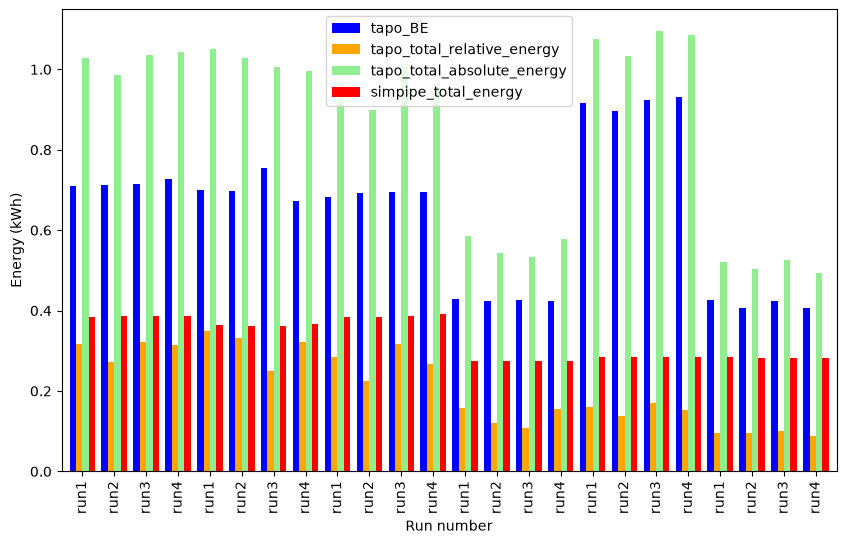

In [16]:
final_results_details.plot(x='runNr', y=['tapo_BE', 'tapo_total_relative_energy', 'tapo_total_absolute_energy', 'simpipe_total_energy'], kind='bar', ylabel="Energy (kWh)", xlabel="Run number", figsize=(10, 6), width=0.8, color=['blue', 'orange', 'lightgreen', 'red'])

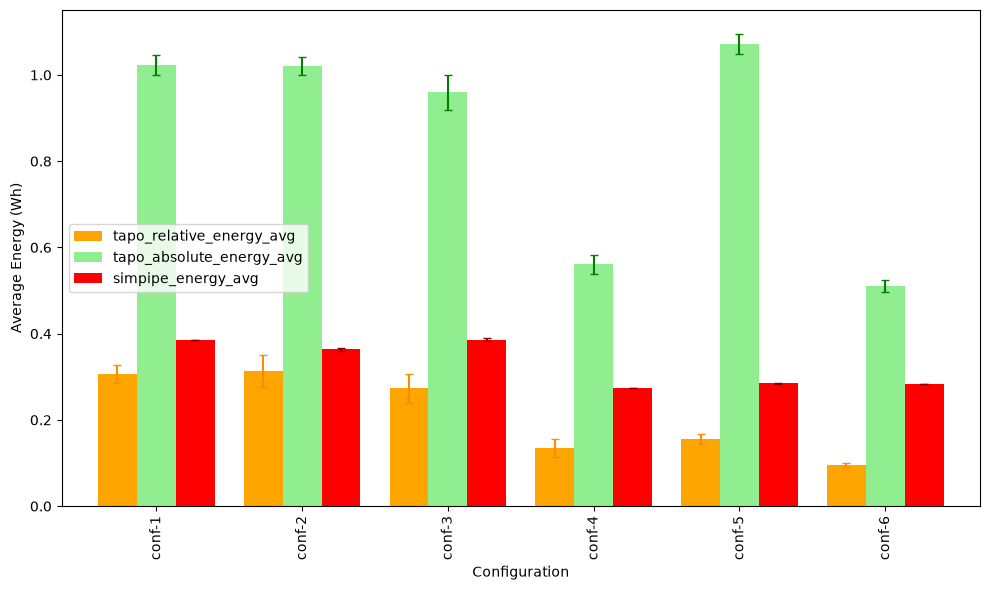

In [17]:
import matplotlib.pyplot as plt

# Create the bar plot
ax = final_results.plot(x='conf', y=['tapo_relative_energy_avg', 'tapo_absolute_energy_avg', 'simpipe_energy_avg'], 
                       kind='bar', ylabel="Average Energy (Wh)", xlabel="Configuration", 
                       figsize=(10, 6), width=0.8, color=['orange', 'lightgreen', 'red'])

# Add error bars
x_pos = np.arange(len(final_results))
width = 0.8 / 3  # width of each bar divided by number of series
#offset = width * 1.5  # offset for positioning bars

# Error bars for each series with correct positioning
ax.errorbar(x_pos - width, final_results['tapo_relative_energy_avg'], 
           yerr=final_results['tapo_relative_energy_std'], fmt='none', color='darkorange', capsize=3)
ax.errorbar(x_pos, final_results['tapo_absolute_energy_avg'], 
           yerr=final_results['tapo_absolute_energy_std'], fmt='none', color='green', capsize=3)
ax.errorbar(x_pos + width, final_results['simpipe_energy_avg'], 
           yerr=final_results['simpipe_energy_std'], fmt='none', color='darkred', capsize=3)

plt.tight_layout()
plt.show()